<img src='./img/up_bann.png' style="display: block; margin: 0 auto;">

*This algorithm comes from an **ESA R&D project** and is validated* 

## APEx 101: Your first algorithm, from catalogue to result

Welcome to the APEx documentation! 📝

The APEx project curates for you the results of various [ESA](https://www.esa.int/) EO projects in a **catalogue of earth observation services** available at the [APEx Algorithm Catalogue](https://algorithm-catalogue.apex.esa.int/). These services are built and maintained by us, which guarantees they have gone through an extensive review and validation process.

The algorithms provided cover a wide spectrum of EO topics with the support of [Sentinel-1](https://sentinels.copernicus.eu/copernicus/sentinel-1), [Sentinel-2](https://sentinels.copernicus.eu/copernicus/sentinel-2) and [Sentinel-3](https://sentinels.copernicus.eu/copernicus/sentinel-3) imagery such as:

- **agriculture** 🌾
- **deforestation** 🪵
- **floods** 💦 
- **change detection services** 🔎
- **wildfires** 🔥 ... etc

In this notebook...

1. We will explore algorithms that are available in the [**APEx Algorithm Services Catalogue**](https://algorithm-catalogue.apex.esa.int/), that run on the [CDSE openEO federation](https://documentation.dataspace.copernicus.eu/APIs/openEO/federation/openeo_federation.html)
2. Then, we will select an algorithm we are interested in...
3. and run it over an area of interest.
4. We will also visualise the results and choose how to store them for further analysis!

### **Prerequisites:**

#### 🛠️ Dependencies 
As we will be working with the APEx algorithms, it is important to install the following dependencies in your desired environment:

```text
- git
- git+https://github.com/ESA-APEx/apex_algorithms.git # The up-to-date version of apex_algorithms
- openeo
- geopandas
- xarray
```

#### 🛰️ openEO 

It is also good to have an understanding of [openEO UDPs](https://open-eo.github.io/openeo-python-client/udp.html), as the APEx algorithms are based on them. You can find examples that explain how to use the `openeo` library in their [Python Client Examples](https://github.com/Open-EO/openeo-community-examples/tree/main/python).

#### 🔐 GitHub Authentication 

The `esa_apex_toolbox` library makes use of **Repository access**, which reads remote GitHub content, not local catalogue changes!<br>

GitHub normally allows 60 unauthenticated **REST API requests per hour per IP address**, shared with other users and tools on that IP. To avoid problems, we advise generating a **GitHub Token**. You can find more information [here](https://esa-apex.github.io/apex_algorithms/toolbox.html#github-authentication).

For this notebook, we defined our token variable as `GH_TOKEN` within our environment.

Once you have completed all these installations and token setups, you are good to go! 🚀 🛰️

### Import Required libraries

In [1]:
from getpass import getpass
import os
from esa_apex_toolbox.algorithms import GithubAlgorithmRepository

import openeo
import geopandas as gpd
import xarray as xr

from IPython.display import display
from shapely.geometry import box
import matplotlib.pyplot as plt
import io

We start by bringing in our github credentials and set the token to access our APEx Catalog.


In [2]:
github_token = os.environ.get('GITHUB_TOKEN') or os.environ.get('GH_TOKEN')
if not github_token:
    github_token = getpass('GitHub token (optional; Enter for unauthenticated access): ') or None


> ##### Remember
> Always **treat a token as a password**: never print it, put it in a committed file, or include it in notebook outputs. Revoke and replace it immediately if exposed; replace it when it expires. Authentication is applied to GitHub API directory requests, not raw catalogue or process-definition downloads.


## 1️⃣ Algorithms Overview

With the `GithubAlgorithmRepository` function, you can set parameters that will help find the specific repository we want to browse.

The APEx algorithms are hosted in the public repository `apex_algorithms` under the `algorithm_catalog` folder.

Once set, with the `list_algorithms` function, you can retrieve an interactive overview of the algorithms available. You can use the search box to find specific algorithms of interest.

In [3]:
repo = GithubAlgorithmRepository(
    owner='ESA-APEx',
    repo='apex_algorithms',
    folder='algorithm_catalog',
    branch='main',
    token=github_token,
)
algorithms = repo.list_algorithms(details=True)
display(algorithms.widget())

### Python Access

If you prefer a programmatic approach, you can define arguments that will allow you to filter the APEx Catalogue based on your interests.

For this, we have two available functions: `list_providers()` or `list_platforms()`. You will get a list of keywords that will help you further refine your search.

To have an overview of all our providers:

In [4]:
repo.list_providers()


['APEx',
 'Brockmann Consult GmbH',
 'CS GROUP - ROMANIA',
 'DHI',
 'DLR',
 'David Frantz',
 'Development Seed',
 'Earth RayView Ltd',
 'EarthDaily',
 'Eurac Research',
 'European Space Agency',
 'GISAT',
 'OBSGESSION',
 'TERRAVISION',
 'Terradue',
 'VITO',
 'Wageningen University & Research']

And for the platforms where we can run the algorithms:

In [5]:
repo.list_platforms()

['CDSE', 'EOxHub', 'GEP', 'TAO', 'Terrascope', 'TiTiler openEO']

Let's say we are interested in discovering algorithms that run in the `CDSE openEO federation`. 

The `list_algorithms` function allows you to set several arguments to refine your search:


```text
- platform
- provider
- keywords
```

For this we can set inside the `platform` argument a list of the platform `ids` related to the CDSE openEO federation:

In [6]:
cdse = repo.list_algorithms(
    platform=["CDSE"],
    details=True,
)

cdse

Algorithm,Provider,Platforms,Keywords
"Urban Heat Island Intensity (JJA)This openEO User Defined Process (UDP) computes Urban Heat Island (UHI) intensity during the summer months (June–August). It processes satellite-derived Land Surface Temperature data and compares urban pixels with surrounding rural reference areas using a configurable kernel size.IDUHI_per_pixelProviderEurac ResearchOrganizationNot specifiedPlatformsCDSEKeywordsUrban Heat Island, Land Surface Temperature, ClimateLicenseNot specifiedServicesopenEO BackendProcessopenEO UDP definitionUHI_per_pixel",Eurac Research,CDSE,"Urban Heat Island, Land Surface Temperature, Climate"
"FORCE level 2Framework for Operational Radiometric Correction for Environmental monitoring (FORCE) Level 2 processor to generate Analysis Ready Data Cubes from Sentinel-2 productsIDforce_level2ProviderDavid FrantzOrganizationGeoinformatics - Spatial Data Science, Trier UniversityPlatformsCDSEKeywordsSentinel-2LicenseNot specifiedServicesCDSE openEO federationProcessNot availableforce_level2",David Frantz,CDSE,Sentinel-2
"FORCE Time Series AnalysisFramework for Operational Radiometric Correction for Environmental monitoring (FORCE) Time Series Analysis processor to generate time series statistics from FORCE level 2 data cubesIDforce_tsaProviderDavid FrantzOrganizationGeoinformatics - Spatial Data Science, Trier UniversityPlatformsCDSEKeywordsSentinel-2LicenseNot specifiedServicesCDSE openEO federationProcessNot availableforce_tsa",David Frantz,CDSE,Sentinel-2
"RAMONA Herbaceous Rangeland Biomass (HRB) country level mosaics for Africa (2022).Generates country-level mosaicks from the (pre-computed) RAMONA monthly HRB products. The original HRB products follow the Sentinel-2 tiling grid in UTM projection. The resulting mosaic is projected in WGS84 / EPSG 4326.IDRAMONA-herbaceous_rangeland_biomass-country-mosaickProviderDHIOrganizationUniversity of Aarhus, DHI, Lund University and GeoVille.PlatformsCDSEKeywordsVegetationLicenseNot specifiedServicesCDSE openEOProcessopenEO Process DefinitionRAMONA-herbaceous_rangeland_biomass-country-mosaick",DHI,CDSE,Vegetation
"Efficient Fusion Algorithm across SpatioTemporal scales (EFAST)EFAST [1] is a method to create time-series with a fine resolution in space and time from a fine spatial but coarse temporal resolution source (Sentinel-2) and a coarse temporal but fine spatial resolution source (Sentinel-3). In comparison to other methods, EFAST aims to achieve results outperforming single-source interpolation without paying the computational cost of other methods leveraging spatial context. [1] Senty, Paul, Radoslaw Guzinski, Kenneth Grogan, et al. “Fast Fusion of Sentinel-2 and Sentinel-3 Time Series over Rangelands.” Remote Sensing 16, no. 11 (2024): 1833.IDefastProviderBrockmann Consult GmbHOrganizationDHIPlatformsCDSEKeywordsSentinel-2, Sentinel-3, Data Analysis and Visualization, Normalized Difference Vegetation Index (NDVI)LicenseNot specifiedServicesCDSE openEO federationProcessopenEO Process Definitionefast",Brockmann Consult GmbH,CDSE,"Sentinel-2, Sentinel-3, Data Analysis and Visualization, Normalized Difference Vegetation Index (NDVI)"
"Bare surface composite (SCMaP)SCMaP is a specialised processing chain for detecting and analysing spectra of bare soils/surfaces. Bare surface and soil pixels are selected using a combined NDVI and NBR index (PVIR2) that optimises the exclusion of photosynthetically active and non-active vegetation. The index is calculated and applied for each individual pixel combined with a regional threshold map. The result is described in here: https://download.geoservice.dlr.de/SOILSUITE/files/EUROPE_5Y/000_Data_Overview/SoilSuite_Data_Description_Europe_V1.pdfIDscmapProviderDLROrganizationNot specifiedPlatformsCDSEKeywordsSoils, Sentinel-2LicenseNot specifiedServicesCDSE openEO federationProcessopenEO Process Definitionscmap",DLR,CDSE,"Soils, Sentinel-2"
"Delineate Anything v2: Global Foundation Model for Field Boundary Det

Once defined, we can retrieve a list of the keywords that are supported within this backend.

This means that the retrieved algorithms will help us run analyses related to these specific topics: 

In [7]:
cdse_keywords = []
[cdse_keywords.append(algorithm.keywords) for algorithm in cdse]
cdse_keywords = list(dict.fromkeys(item for sublist in cdse_keywords for item in sublist))
cdse_keywords

['Urban Heat Island',
 'Land Surface Temperature',
 'Climate',
 'Sentinel-2',
 'Vegetation',
 'Sentinel-3',
 'Data Analysis and Visualization',
 'Normalized Difference Vegetation Index (NDVI)',
 'Soils',
 'Agriculture',
 'Land Use/Land Cover Classification',
 'Energy Production/Use',
 'Solar Energy Production/Use',
 'Sentinel-1',
 'Radar',
 'Change Detection Services',
 'Land Use/Land Cover Change',
 'Deforestation',
 'Leaf Area Index (LAI)',
 'Forests',
 'Geology',
 'Mining/Drilling Site',
 'Mineral Resources',
 'Fraction of Absorbed Photosynthetic Active Radiation (fAPAR)',
 'Fraction of Vegetation Coverage (fCOVER)',
 'Natural Hazards',
 'Wildfires',
 'Statistics',
 'Digital Elevation/Terrain Model (DEM)',
 'ECMWF ERA5']

Let's refine our search once more and retrieve all the algorithms related to Agriculture. To get a fast overview, we can simply call arguments such as `title`, `id` and `provider`.

In [8]:
agriculture_alg = repo.list_algorithms(
    platform=["CDSE"],
    keywords=["Agriculture"],
    details=True,
)

for algorithm in agriculture_alg:
    print(algorithm.title, "|  ", algorithm.id , "  |",algorithm.provider )

Delineate Anything v2: Global Foundation Model for Field Boundary Detection |   delineate_anything   | European Space Agency
Bare Soil Index (BSI) |   bsi   | TERRAVISION
Biophysical parameters calculation |   biopar   | VITO
Parcel Delineation based on ML using Sentinel-2 |   parcel_delineation   | VITO
Plant Phenology Index (PPI) |   ppi   | VITO
Surface Soil Moisture from Sentinel‑1 using Change Detection |   sentinel1_soil_moisture   | VITO
Variability maps |   variabilitymap   | VITO
ESA worldcereal global crop extent detector |   worldcereal_crop_extent   | VITO
ESA worldcereal global crop type detector |   worldcereal_crop_type   | VITO
WorldAgroCommodities (WAC) Processing Pipeline |   world_agrocommodities   | Wageningen University & Research


## 2️⃣ Accessing an algorithm

From the filtered list above, we can access any algorithm we are interested in with its `id`.

For this, we can use the `get_algorithm` function and the **algorithm** `id` we retrieved earlier. This will allow us to get the link access to identify our algorithm and run it in the backend we have chosen (the CDSE OpenEO federation).

Let's call it directly for the **Bare Soil Index** algorithm, which is the second retrieved algorithm from our agricultural search

In [9]:
bsi_algorithm = repo.get_algorithm(agriculture_alg[1].id)
bsi_algorithm

Algorithm(id='bsi', title='Bare Soil Index (BSI)', description='Estimates the Bare Soil Index (BSI) for agricultural fields from Sentinel-2 satellite imagery.', udp_link=UdpLink(href='https://raw.githubusercontent.com/ITA-TECNOLOGIA/Ard-Terravision/5a816006b2948d2bcbc403c6bcdeb6792086082f/src/main/python/utils/openeo_udp/bsi.json', title='openEO Process Definition'), service_links=[ServiceLink(href='https://openeofed.dataspace.copernicus.eu', title='CDSE openEO Federation')], license=None, organization='VITO', provider='TERRAVISION', platforms=['CDSE'], keywords=['Agriculture', 'Soils', 'Sentinel-2', 'Data Analysis and Visualization'])

Once we have accessed the algorithm, we can call the **process URL**.

APEx offers two processing algorithm backends:

- **openEO** : the algorithms are provided as [User Defined Processes](https://open-eo.github.io/openeo-python-client/udp.html) (UDP's) from openEO; and are accessed through the `udp_link` attribute within the algorithm.
- **OGC API**: the algorithms are executed via standard HTTP REST calls and provide STAC item URLs as input.
<br><br>

> ##### Stay tuned!
> New tutorials on how to use both approaches are coming!.

With this information, you will be able to choose the correct backend authentication method you are interested in.

In the case of `bsi`, we will retrieve the `udp_link`.<br>
This attribute will help us feed directly to the CDSE openEO federation all the steps that the backend needs to follow to execute the algorithm smoothly!

By calling the `udp_link.href` attribute for the selected algorithm, we will obtain our link.

In [10]:
bsi_link = bsi_algorithm.udp_link.href
bsi_link

'https://raw.githubusercontent.com/ITA-TECNOLOGIA/Ard-Terravision/5a816006b2948d2bcbc403c6bcdeb6792086082f/src/main/python/utils/openeo_udp/bsi.json'

> ##### Whats an UDP?
> The openEO API enables to store subchains on the back-end as a so called **user-defined process**. They allow to build our own library of reusable building blocks.
> APEx algorithms that work with the openEO backend make use of this UDPs as they standardise parameter names and types, interoperability for the algorithms allowing them to run smoothly across different cloud environments.


## 3️⃣ Authentication

As we have discussed earlier, the Bare Soil Index (BSI) algorithm runs in the CDSE openEO federation, and thus requires you to have credentials in the [CDSE](https://dataspace.copernicus.eu/).<br>

If you are still not part of the ecosystem, you can do it [here](https://identity.dataspace.copernicus.eu/auth/realms/CDSE/login-actions/registration?client_id=account-console&tab_id=4qvKTpPuSyA&client_data=eyJydSI6Imh0dHBzOi8vaWRlbnRpdHkuZGF0YXNwYWNlLmNvcGVybmljdXMuZXUvYXV0aC9yZWFsbXMvQ0RTRS9hY2NvdW50LyIsInJ0IjoiY29kZSIsInJtIjoicXVlcnkiLCJzdCI6ImQ4ZTBkNDNmLWNiNDctNDViYi04NGI2LWMwMThlZTBlYmNiYyJ9).

We can establish our connection with the `openeo.connect` function. Once we run the cell, we will be redirected to an interactive login flow in a browser.

In [11]:
connection = openeo.connect("openeofed.dataspace.copernicus.eu").authenticate_oidc()

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=LAIG-VUZX 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.


> ##### **Note**
> When the openEO Python client library can find a valid refresh token on its system, this will be a non-interactive operation. This makes it a viable option for non-interactive and machine-to-machine authentication.<br>
<br>
> To explore this automated process you can read further [here](https://documentation.dataspace.copernicus.eu/APIs/openEO/authentication.html#refresh-tokens)


And voilà ! We got all the set up we need to run our first APEx algorithm in an area we are interested!

## 4️⃣ Defining an Area of interest : Kakhovka Dam

Now, we will define the area of interest we want to process.

An interesting case study is quantifying land surface changes triggered by the breach of the Kakhovka Dam, located in the Kherson Oblast, Ukraine, on June 6, 2023.

For this, we can evaluate conditions during late summer 2023. Analysing the site approximately two months post-event serves two analytical goals:
1. delineating the fully desiccated reservoir bed during its phase of maximum spectral bare-soil reflectance (BSI peak)
2. capturing the initial impact of canal cutoffs across surrounding agricultural lands.


The openEO UDP backend, understands this area in the dictionary format:

<center>

``` text
{"west": value, "south": value, "east": value, "north": value}
```
</center>

and the time period we are interested in as:

<center>

``` text
["YYYY-MM-DD", "YYYY-MM-DD"]
```
</center>

We set an Area of Interest (AOI) spanning the reservoir basin and extract a desired Sentinel-2 scene from August 24, 2023.


In [12]:
geometry = (33.272095,46.671585,33.609924,46.889762)
shape = {"west": geometry[0], "south": geometry[1], "east": geometry[2], "north": geometry[3]}
start_date, end_date = ["2023-08-24", "2023-08-24"]

# Our area of interest
aoi = gpd.GeoSeries(box(*geometry), crs="EPSG:4326")
aoi.explore(color="red")

> ##### Note
> This image was revised during development, and we have ensured it contains less than 3% cloud coverage.

## 5️⃣ Setting parameters

Once we have defined the parameters to run our algorithm, we can generate our datacube.

For this, we call our openEO `datacube_from_process` function. Then we will set the following parameters:

- `"Name of our Process"` : the name our process graph will display
- `namespace`: the `udp_link` we retrieved from the APEx Catalogue
- `temporal_extent`: the temporal extent we defined. In this case we will onlt retrieve images that are present on the same day
- `spatial_extent` : our polygon dictionary we defined

In [13]:
bsi = connection.datacube_from_process(
    "BSI",
    namespace=bsi_link,
    temporal_extent=[start_date, end_date],
    spatial_extent=shape,
)

bsi

As a result, we can visualise our process graph.
<br>

For this example, we will just run the **BSI** process, but remember: this algorithm can be a step in our process; the process graph will be as complex as our EO workflow defines!

Finally, to perform our job and send it to the CDSE openEO federation backend, we can set the `create_job` function; this allows us to define:
- `title` : a dynamic overview based on the inputs we defined
- `out_format` : we can select the storage format we want to generate

> ##### Recommendation
> The APEx Catalogue defines the output format for each algorithm. In the case of `bsi`, the result is a `netcdf`.


## 6️⃣ Running an algorithm

To visualise the dynamic execution, we can call the `start_and_wait` function. This will add a progress bar for you to monitor the job execution live!

In [14]:
job = bsi.create_job(
        title=f'BSI calculation for {start_date} to {end_date}',
        out_format="NetCDF")
job.start_and_wait()

0:00:00 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': send 'start'
0:00:03 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': created (progress 0%)
0:00:08 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:00:15 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:00:23 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:00:33 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:00:45 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:01:01 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': queued (progress 0%)
0:01:20 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': running (progress N/A)
0:01:44 Job 'cdse-j-261111144218469db2fcc13a0fe5138f': finished (progress 100%)


<BatchJob job_id='cdse-j-261111144218469db2fcc13a0fe5138f'>

> ##### Note
> For this example we will retrieve only one day. When you would like to run the algorithm over a specific period, you can state so by defining a `starting` and `ending` date.

## 7️⃣ Accessing the results

And congratulations! 🥳 🎉 You have run your first APEx process!!!

The last step is bringing your results into a variable; you can do this by calling the `get_results` function on the job you created, and if you want to save the results, just set up your path.

In the downloaded result you will find:

```text
your-folder/
├── job-results.json
└── openEO.nc
```

- `job-results.json` : this is the metadata descriptor for your job execution.
- `openEO.nc` : this is your actual processed Earth observation data (the primary result).

Of course, you can costumise yourself the desired names to your results to automate your EO workflow if desired! If you want to download the results, just run the following commented-out cell.


In [15]:
# job.get_results().download_files("your-folder")
# print("Finished. Downloaded results to ./your-folder")

For our demonstration, we will stream the results from openEO directly as we look forward to visualising them.

## 👀 Exploring the results

To get an overview of the default settings, we can access the data and explore the results of our BSI. We will retrieve only the `.nc` file that stores the result of our process.

We can achieve this by:

- Calling the result asset URL (stored under `href`)
- Adding our authentication header (through `connection.session.get `). As we have provided our credentials, it will be straightforward
- Opening our data with xarray

In [16]:
results = job.get_results()
# get our request
assets = results.get_assets()
nc_asset = next(a for a in assets if a.key.endswith(".nc"))
asset_url = nc_asset.href
asset_url

# we get the Bearer authentication headers from openEO connection
response = connection.session.get(asset_url)
response.raise_for_status()

# stream our netcdf directly into xarray
ds = xr.open_dataset(io.BytesIO(response.content), engine="h5netcdf")

ds

<xarray.Dataset> Size: 25MB
Dimensions:  (t: 1, y: 2440, x: 2594)
Coordinates:
  * t        (t) datetime64[ns] 8B 2023-08-24
  * y        (y) float64 20kB 5.193e+06 5.193e+06 ... 5.169e+06 5.169e+06
  * x        (x) float64 21kB 5.207e+05 5.207e+05 ... 5.466e+05 5.467e+05
Data variables:
    crs      |S1 1B ...
    var      (t, y, x) float32 25MB ...
Attributes:
    Conventions:  CF-1.9
    institution:  Copernicus Data Space Ecosystem openEO API - 0.74.0a6.dev20...
    description:  
    title:

When we explore our result we see we got only the timestep for our desired day.<br>
We can visualise the result.

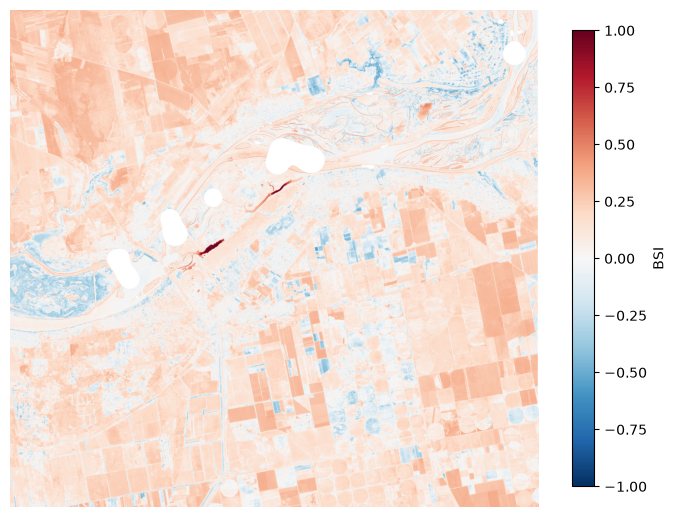

In [17]:
cmin = -1
cmax = 1
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    ds["var"].squeeze().values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    origin="upper",  # <-- Changed from "lower" to "upper"
    aspect="equal",
)

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("BSI")

ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### What the map shows

1. **BSI** values run from -1 to 1. Most pixels fall between about 0.1 and 0.3, which is typical of bare or sparsely vegetated soil.
2. The former reservoir bed shows high BSI values, where the blue of vegetation and water was before. This is consistent with the bed being bare soil.
3. The farmland fields affected by the irrigation shortage can be seen clearly.
4. The white patches are invalid pixels. The algorithm filtered them out automatically for us.

To explore the whole analysis, and see the APEx algorithms applied check out the [BSI workflow notebook]() (in preparation). It monitors BSI changes along a defined timeline!

## Takeaways



In this notebook we explored the [**APEx Catalogue**](https://algorithm-catalogue.apex.esa.int/), selected the Bare Soil Index (`bsi`) algorithm, ran it on the [CDSE openEO federation](https://documentation.dataspace.copernicus.eu/APIs/openEO/federation/openeo_federation.html) for the area around the Kakhovka Reservoir, and retrieved the result.

We also learned that it takes us 7 steps to apply a curated and validated algorithm result of projects that had been carried out at the European level!

They can summarised in:

1. Identifying the algorithm in the catalogue
2. Accessing its process link (UDP)
3. Authenticating to the CDSE openEO federation
4. Defining the area and the date
5. Building the process
6. Running our job
7. Accessing our results


Stay tuned for the next developments that our team will bring to you in the following months! 🛰️ 🚀

<img src='./img/low_bann.png' style="display: block; margin: 0 auto;">